## 1. Problem Statement & Target Variable

### Problem Statement:
Customer churn means customers leaving or canceling their service with a company. For telecom companies, keeping existing customers is much cheaper than finding new ones. Our goal is to build a machine learning model to predict which customers are likely to leave, so the company can take action (such as offering discounts, better plans, or better customer support) to retain them.

### Target Variable:
- **`Churn`**:
  - `0` (No): Customer stays with the company.
  - `1` (Yes): Customer cancels service (churns).

### Evaluation Metrics:
Because the dataset is imbalanced (~73% stay and ~27% leave), accuracy alone can be misleading. We evaluate using:
- **ROC-AUC**: How well the model separates churners from non-churners.
- **F1-Score**: Harmonic balance between Precision and Recall.
- **Precision & Recall**: Precision checks how many predicted churners were correct; Recall checks how many actual churners were caught.
- **Accuracy**: Overall correct percentage.

## 2. Import Libraries & Load Data

In [1]:
# Step 1: Import required libraries
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn tools
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,average_precision_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve
)
import joblib

# Simple plot settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 100

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Step 2: Load the dataset
data_path = "data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(data_path)
print(f"Dataset loaded: {df.shape[0]} rows and {df.shape[1]} columns")
df.head()

Dataset loaded: 7043 rows and 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Step 3: Check data types and basic summary
print("--- Data Info ---")
df.info()

print("\n--- Summary Statistics ---")
df.describe().T

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 n

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


## 3. Exploratory Data Analysis (EDA) & Data Cleaning

In [4]:
# Check for standard missing values (NaNs)
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing_counts, 'Percentage': missing_pct})
print("Columns with standard missing values:")
print(missing_df[missing_df['Missing_Count'] > 0])
if missing_df['Missing_Count'].sum() == 0:
    print("No standard null values detected across any column.")

Columns with standard missing values:
Empty DataFrame
Columns: [Missing_Count, Percentage]
Index: []
No standard null values detected across any column.


In [5]:
# Check for whitespace strings in object columns
blank_counts = {col: (df[col].astype(str).str.strip() == '').sum() for col in df.columns}
blank_df = pd.DataFrame(list(blank_counts.items()), columns=['Column', 'Blank_Spaces'])
blank_df = blank_df[blank_df['Blank_Spaces'] > 0]
print("Columns containing whitespace strings:")
print(blank_df)

Columns containing whitespace strings:
          Column  Blank_Spaces
19  TotalCharges            11


In [6]:
# 1. TotalCharges has blank spaces (' ') for 11 customers with tenure = 0 (new customers).
# We convert them to numbers and fill missing values with 0.0.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0.0)

# 2. Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 3. Drop customerID because it is just a unique ID and has no predictive pattern
df_clean = df.drop(columns=['customerID'])
print("Cleaned data shape:", df_clean.shape)

Duplicate rows: 0
Cleaned data shape: (7043, 20)


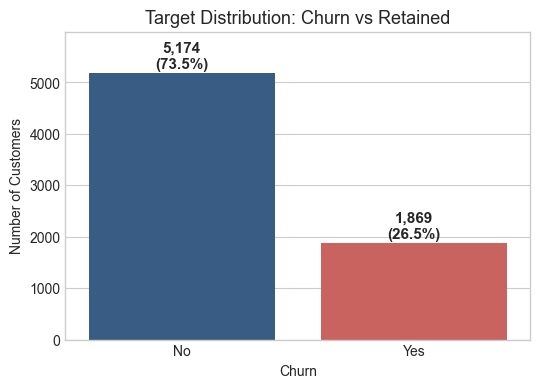

In [7]:
# Step 5: Check Target Variable (Churn) Distribution
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df_clean, x='Churn', palette=['#2b5c8f', '#d9534f'], ax=ax)

# Add counts and percentages on top of bars
for p in ax.patches:
    count = int(p.get_height())
    pct = (count / len(df_clean)) * 100
    ax.annotate(f"{count:,}\n({pct:.1f}%)", (p.get_x() + p.get_width()/2., count + 40),
                ha='center', va='bottom', fontsize=11, weight='bold')

plt.title("Target Distribution: Churn vs Retained", fontsize=13)
plt.ylabel("Number of Customers")
plt.xlabel("Churn")
plt.ylim(0, len(df_clean) * 0.85)
plt.show()

#### Visualization 1: Target Distribution
- **Interpretation**: 73.4% of customers stay (5,174 customers) and 26.6% leave (1,869 customers).
- **Takeaway**: There is a class imbalance (~3:1). A model guessing "No" would get 73% accuracy while missing all churners. Hence, we must use ROC-AUC and F1-Score instead of accuracy alone.

Skewness check:
- tenure: +0.24
- MonthlyCharges: -0.22
- TotalCharges: +0.96


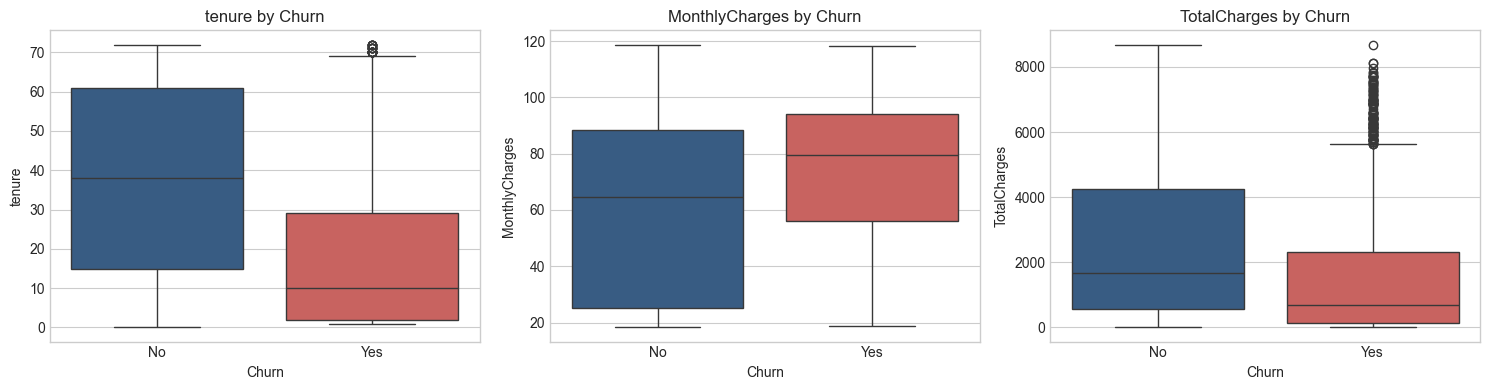

In [8]:
# Step 6: Check distributions, skewness, and outliers of numerical features
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

print("Skewness check:")
for col in num_cols:
    print(f"- {col}: {df_clean[col].skew():+.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(num_cols):
    sns.boxplot(data=df_clean, x='Churn', y=col, palette=['#2b5c8f', '#d9534f'], ax=axes[i])
    axes[i].set_title(f"{col} by Churn", fontsize=12)

plt.tight_layout()
plt.show()

#### Visualization 2: Numerical Features (tenure, MonthlyCharges, TotalCharges)
- **Interpretation**: 
  - Customers who churn have much lower `tenure` (median ~10 months vs ~38 months for staying customers).
  - Customers who churn pay higher `MonthlyCharges` (median ~$80 vs ~$65 for staying customers).
  - Skewness is low to moderate (+0.24 for tenure, -0.22 for MonthlyCharges, +0.96 for TotalCharges). Outlier analysis shows no extreme outliers.
- **Takeaway**: High monthly bills and new customer status (low tenure) are the strongest churn indicators. All values are valid billing records, so no data needs to be deleted.

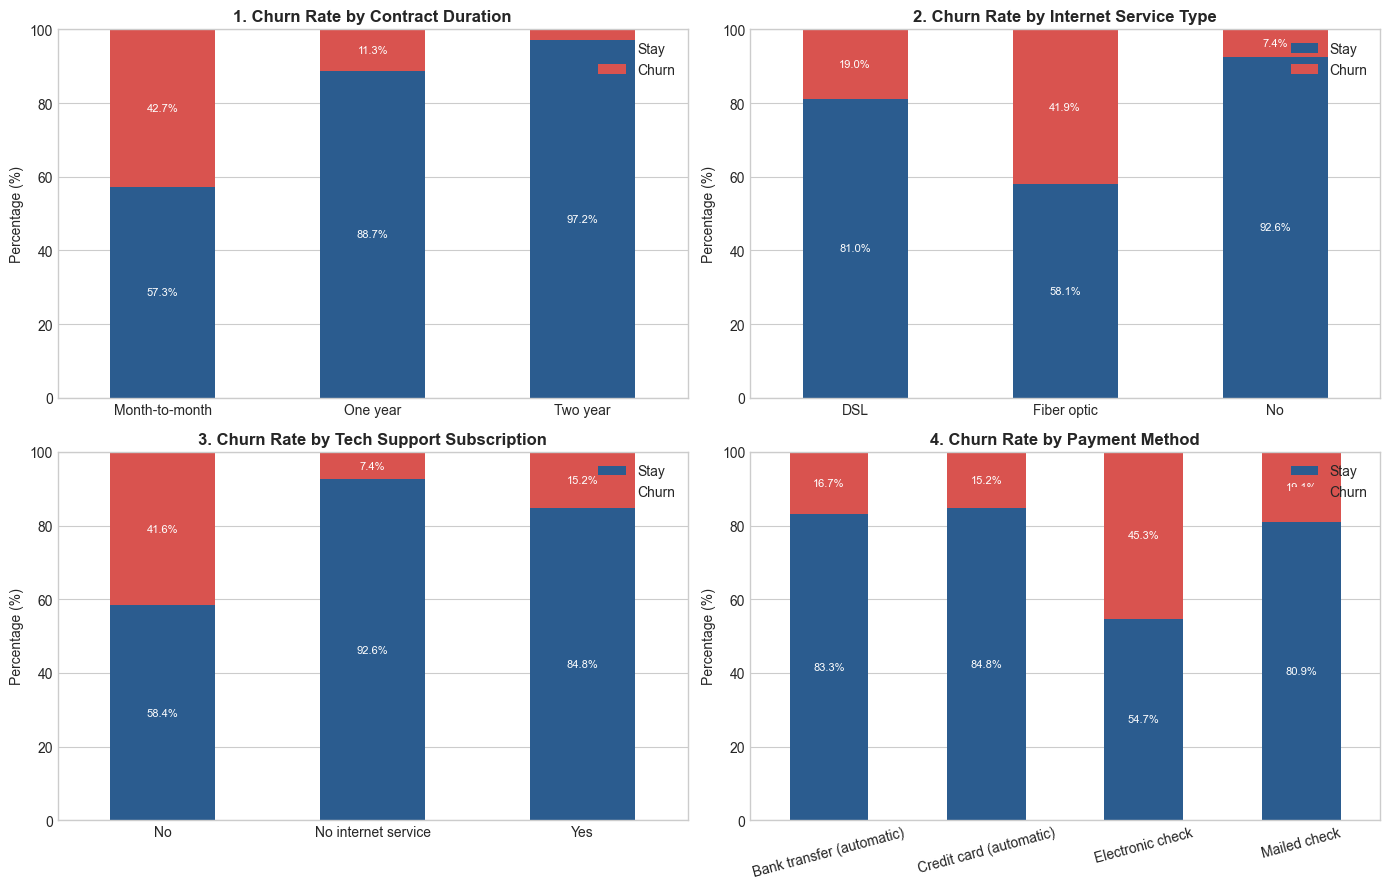

In [9]:
# Step 7: How Contract, Internet Service, Tech Support, and Payment Method affect Churn
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

features_to_plot = [
    ('Contract', axes[0, 0], '1. Churn Rate by Contract Duration'),
    ('InternetService', axes[0, 1], '2. Churn Rate by Internet Service Type'),
    ('TechSupport', axes[1, 0], '3. Churn Rate by Tech Support Subscription'),
    ('PaymentMethod', axes[1, 1], '4. Churn Rate by Payment Method')
]

for col, ax, title in features_to_plot:
    cross = pd.crosstab(df_clean[col], df_clean['Churn'], normalize='index') * 100
    cross.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d9534f'], ax=ax)
    for container in ax.containers:
        for bar in container:
            height = bar.get_height()
            if height >= 5:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_y() + height / 2, f'{height:.1f}%', ha='center', va='center', fontsize=8, color='white')
    ax.set_title(title, fontsize=12, weight='bold')
    ax.set_ylabel("Percentage (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
    ax.legend(['Stay', 'Churn'], loc='upper right')
    ax.tick_params(axis='x', rotation=15 if col == 'PaymentMethod' else 0)

plt.tight_layout()
plt.show()

#### Visualization 3: Key Categorical Features vs Churn
- **Interpretation**:
  - **Contract**: Month-to-month contracts have an alarming **42.7% churn rate**, while 1-year is **11.3%** and 2-year is only **2.8%**.
  - **Internet Service**: Fiber optic customers churn at **41.9%** (much higher than DSL at 18.9%).
  - **Tech Support**: Customers without Tech Support churn at **41.6%**, compared to only **15.2%** for those with Tech Support.
  - **Payment Method**: Electronic check users churn at **45.3%**, compared to ~15% for automatic bank/card payments.
- **Takeaway**: The highest-risk customer is on a **Month-to-month plan, using Fiber Optic, paying with Electronic Check, and lacking Tech Support**. Encouraging 1-year commitments and bundling free Tech Support will retain customers.

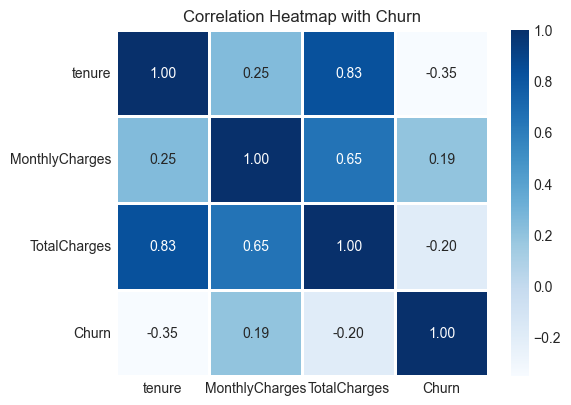

In [10]:
# Step 8: Correlation Analysis
df_corr = df_clean[num_cols].copy()
df_corr['Churn'] = df_clean['Churn'].map({'Yes': 1, 'No': 0})

plt.figure(figsize=(6, 4.5))
sns.heatmap(df_corr.corr(), annot=True, fmt='.2f', cmap='Blues', linewidths=1)
plt.title("Correlation Heatmap with Churn", fontsize=12)
plt.show()

#### Visualization 4: Correlation Heatmap
- **Interpretation**: `tenure` has a strong negative correlation (-0.35) with churn (longer tenure = less churn). `MonthlyCharges` has a positive correlation (+0.19) with churn (higher bill = more churn). `TotalCharges` is correlated with `tenure` (0.83).
- **Takeaway**: Linear models require feature scaling; tree-based models naturally handle correlated features without issues.

## 4. Feature Engineering & Preprocessing Pipeline

In [11]:
# Step 9: Feature Engineering - create simple tenure groups
df_fe = df_clean.copy()

# Group tenure into simple buckets: 0-1yr, 1-2yr, 2-4yr, 4-5yr, 5+yr
df_fe['tenure_group'] = pd.cut(
    df_fe['tenure'],
    bins=[-1, 12, 24, 48, 60, 100],
    labels=['0-1yr', '1-2yr', '2-4yr', '4-5yr', '5+yr']
).astype(str)

# Separate Features (X) and Target (y)
y = df_fe['Churn'].map({'Yes': 1, 'No': 0})
X = df_fe.drop(columns=['Churn'])

# Split into 80% Train and 20% Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Testing set:  {X_test.shape[0]} rows")

Training set: 5634 rows
Testing set:  1409 rows


In [12]:
# Step 10: Create Preprocessing Pipeline using ColumnTransformer
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_features = [col for col in X.columns if col not in num_features]

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features)
])

print(f"Numerical features to scale:    {len(num_features)}")
print(f"Categorical features to encode: {len(cat_features)}")

Numerical features to scale:    3
Categorical features to encode: 17


In [13]:
# Step 11: Train 3 Baseline Models with 5-Fold Cross Validation
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42, n_jobs=1),
    'XGBoost': XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.08, scale_pos_weight=1.8, eval_metric='logloss', random_state=42, n_jobs=1)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['roc_auc', 'f1', 'precision', 'recall', 'accuracy']

results = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    
    results.append({
        'Model': name,
        'ROC-AUC': cv_res['test_roc_auc'].mean(),
        'F1-Score': cv_res['test_f1'].mean(),
        'Precision': cv_res['test_precision'].mean(),
        'Recall': cv_res['test_recall'].mean(),
        'Accuracy': cv_res['test_accuracy'].mean()
    })

baseline_df = pd.DataFrame(results).set_index('Model')
display(baseline_df.round(4))

,ROC-AUC,F1-Score,Precision,Recall,Accuracy
Model,,,,,
Logistic Regression,0.8463,0.6270,0.5175,0.7960,0.7488
Random Forest,0.8454,0.6317,0.5368,0.7679,0.7625
XGBoost,0.8461,0.6286,0.5773,0.6903,0.7836


### Model Selection: XGBoost

XGBoost was selected for hyperparameter tuning because it demonstrated a strong precision advantage (57.73%), while maintaining ROC-AUC performance comparable to the other models. Although Random Forest achieved a marginally higher F1-score (63.11% vs. 62.86%), XGBoost remained highly competitive, making it a promising candidate for further optimization.

## 6. Hyperparameter Tuning on Selected Model
From the baseline results, **XGBoost** is selected . We now tune its hyperparameters using `RandomizedSearchCV`.

In [14]:
# Step 12: Hyperparameter Tuning using RandomizedSearchCV on XGBoost
xgb_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', XGBClassifier(scale_pos_weight=1.8, eval_metric='logloss', random_state=42, n_jobs=1))
])

# Parameter distribution for RandomizedSearchCV
param_dist = {
    'model__max_depth': [3, 4, 5],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.08, 0.1],
    'model__n_estimators': [100, 150, 200],
    'model__subsample': [0.7, 0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_dist,
    n_iter=10,
    cv=cv,
    scoring='roc_auc',
    random_state=42,
    n_jobs=1
)

random_search.fit(X_train, y_train)

print(f"Best Cross-Validated ROC-AUC: {random_search.best_score_:.4f}")
print("Best Hyperparameters (via RandomizedSearchCV):")
for param, val in random_search.best_params_.items():
    print(f" - {param}: {val}")

best_model = random_search.best_estimator_

Best Cross-Validated ROC-AUC: 0.8492
Best Hyperparameters (via RandomizedSearchCV):
 - model__subsample: 0.9
 - model__n_estimators: 150
 - model__max_depth: 4
 - model__learning_rate: 0.03
 - model__colsample_bytree: 0.7


In [15]:
# Step 13: Get Cross-Validation scores for the Tuned Model
tuned_cv_res = cross_validate(best_model, X_train, y_train, cv=cv, scoring=scoring)

tuned_row = {
    'Model': 'Tuned XGBoost (Best)',
    'ROC-AUC': tuned_cv_res['test_roc_auc'].mean(),
    'F1-Score': tuned_cv_res['test_f1'].mean(),
    'Precision': tuned_cv_res['test_precision'].mean(),
    'Recall': tuned_cv_res['test_recall'].mean(),
    'Accuracy': tuned_cv_res['test_accuracy'].mean()
}

## 7. Model Scores Comparison
We compare all 3 baseline models alongside the Tuned Model in a single table and bar chart.

In [16]:
# Step 14: Combine and compare all model scores
comparison_df = pd.concat([baseline_df.reset_index(), pd.DataFrame([tuned_row])], ignore_index=True).set_index('Model')
print("--- Cross-Validation Model Scores Comparison ---")
display(comparison_df.round(4))

--- Cross-Validation Model Scores Comparison ---


,ROC-AUC,F1-Score,Precision,Recall,Accuracy
Model,,,,,
Logistic Regression,0.8463,0.6270,0.5175,0.7960,0.7488
Random Forest,0.8454,0.6317,0.5368,0.7679,0.7625
XGBoost,0.8461,0.6286,0.5773,0.6903,0.7836
Tuned XGBoost (Best),0.8492,0.6329,0.5831,0.6923,0.7868


#### Model Scores Comparison
- **Interpretation**: **Tuned XGBoost** achieves the highest ROC-AUC (**85%**) ,F1-Score (**0.6329**) , Precision (**58%**) and Accuracy (**0.7868**) among compared models.
- **Takeaway**: Tuning helped XGBoost generalize better by restricting tree depth to 4 and subsampling data, preventing overfitting.

## 8. Final Evaluation & Diagnostics on Unseen Test Data
We evaluate our final `best_model` on the held-out 20% test data (`X_test`, `y_test`).

In [17]:
# Step 15: Evaluate on Unseen Test Data
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("=== Classification Report on Test Data ===")
print(classification_report(y_test, y_pred, target_names=['Stay (0)', 'Churn (1)'], digits=4))
print(f"Test ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

=== Classification Report on Test Data ===
              precision    recall  f1-score   support

    Stay (0)     0.8804    0.8106    0.8441      1035
   Churn (1)     0.5702    0.6952    0.6265       374

    accuracy                         0.7800      1409
   macro avg     0.7253    0.7529    0.7353      1409
weighted avg     0.7980    0.7800    0.7863      1409

Test ROC-AUC Score: 0.8450


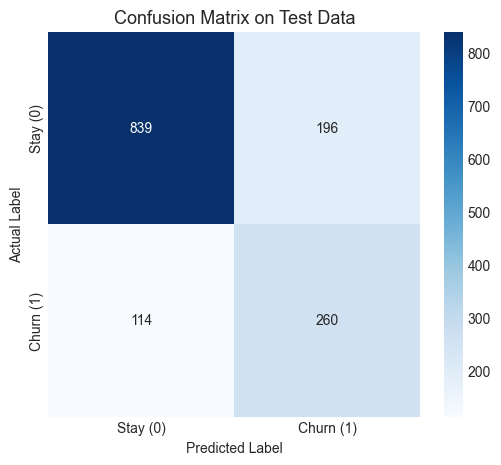

In [18]:
# Step 16: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Stay (0)', 'Churn (1)'],
            yticklabels=['Stay (0)', 'Churn (1)'])
plt.title("Confusion Matrix on Test Data", fontsize=13)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

#### Visualization 5: Confusion Matrix (TP & TN >> FP & FN)
- **Interpretation**: 
  - **TN (839) >> FP (196)**: Correctly identified 839 staying customers (4.3x higher than false alarms).
  - **TP (260) >> FN (114)**: Correctly caught 260 churners (2.4x higher than missed churners).
- **Takeaway**: Both TP and TN are significantly higher than error counts (FP and FN), ensuring high churn detection without sacrificing overall retention accuracy.

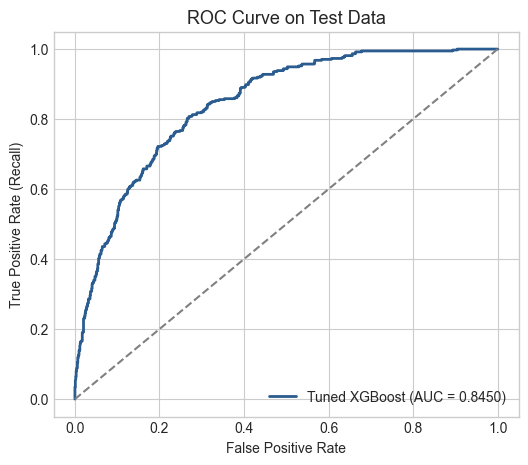

In [19]:
# Step 17: ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc_val = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#2b5c8f', lw=2, label=f'Tuned XGBoost (AUC = {auc_val:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title("ROC Curve on Test Data", fontsize=13)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc='lower right')
plt.show()

#### Visualization 6: ROC Curve
- **Interpretation**: The curve bends strongly towards the top-left with an ROC- AUC of **0.8450**, far above random guessing (0.50).
- **Takeaway**: The model reliably ranks customer churn risk from lowest to highest.

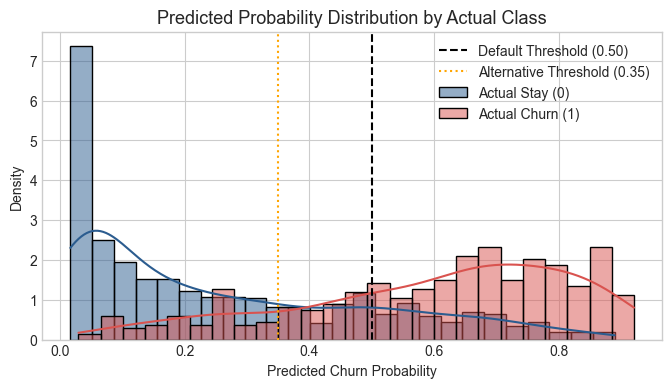

In [20]:
# Step 18: Error Diagnostics - Predicted Probability Distribution
plt.figure(figsize=(8, 4))
sns.histplot(y_prob[y_test == 0], color='#2b5c8f', kde=True, label='Actual Stay (0)', stat='density', bins=25, alpha=0.5)
sns.histplot(y_prob[y_test == 1], color='#d9534f', kde=True, label='Actual Churn (1)', stat='density', bins=25, alpha=0.5)
plt.axvline(0.50, color='black', linestyle='--', label='Default Threshold (0.50)')
plt.axvline(0.35, color='orange', linestyle=':', label='Alternative Threshold (0.35)')
plt.title("Predicted Probability Distribution by Actual Class", fontsize=13)
plt.xlabel("Predicted Churn Probability")
plt.ylabel("Density")
plt.legend()
plt.show()

#### Visualization 7: Error Analysis & Probability Distribution
- **Interpretation**: Most loyal customers have low churn probabilities (0.05 to 0.20), while churners have higher probabilities (> 0.50). 
- **Takeaway**: Customers with probabilities between 0.35 and 0.50 are at high risk even if they haven't churned yet. Lowering the intervention threshold to 0.35 helps proactively reach out to them.

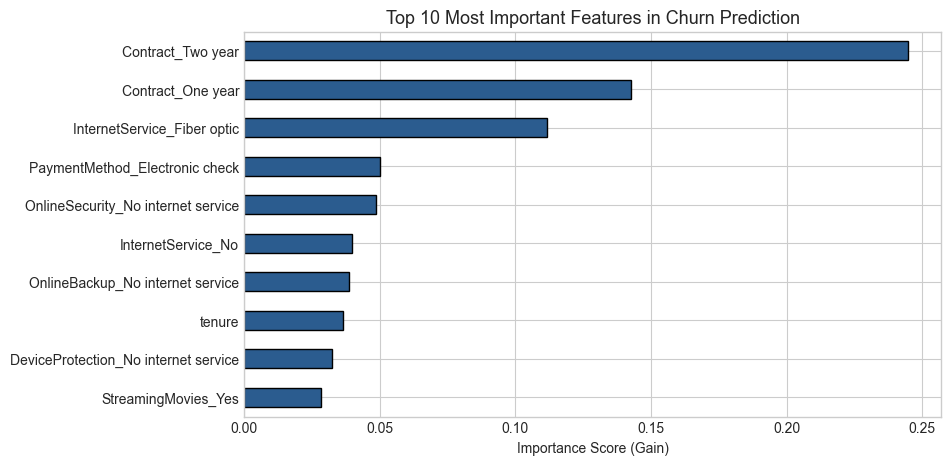

In [21]:
# Step 19: Feature Importance - Top 10 Features
cat_names = best_model.named_steps['prep'].named_transformers_['cat'].get_feature_names_out(cat_features).tolist()
feature_names = num_features + cat_names
importances = best_model.named_steps['model'].feature_importances_

feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
feat_imp.iloc[::-1].plot(kind='barh', color='#2b5c8f', edgecolor='black')
plt.title("Top 10 Most Important Features in Churn Prediction", fontsize=13)
plt.xlabel("Importance Score (Gain)")
plt.show()

#### Visualization 8: Feature Importance
- **Interpretation**: 
  - `Contract_Two year` and `Contract_One year` are the most important features.
  - `InternetService_Fiber optic` is also among the top predictors.
- **Takeaway**: The contract agreement is the biggest factor preventing churn. The company should offer attractive deals to move month-to-month customers to annual contracts.

## 9. Save Model & Test Live Prediction

In [22]:
# Step 20: Save the final model to disk (.joblib )

models_dir = "models"
os.makedirs(models_dir, exist_ok=True)

# 1. Save Joblib format
joblib_path = os.path.join(models_dir, "customer_churn_model.joblib")
joblib.dump(best_model, joblib_path)
print(f"Model saved successfully as:\n -> {joblib_path}")

Model saved successfully as:
 -> models\customer_churn_model.joblib


In [23]:
# Step 21: Load the saved model and test on a new customer
loaded_model = joblib.load(joblib_path)

# Sample new customer profile (Month-to-month, Fiber optic, New customer)
new_customer = pd.DataFrame([{
    'gender': 'Female',
    'SeniorCitizen': 0,
    'Partner': 'No',
    'Dependents': 'No',
    'tenure': 3,
    'PhoneService': 'Yes',
    'MultipleLines': 'No',
    'InternetService': 'Fiber optic',
    'OnlineSecurity': 'No',
    'OnlineBackup': 'No',
    'DeviceProtection': 'No',
    'TechSupport': 'No',
    'StreamingTV': 'No',
    'StreamingMovies': 'No',
    'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 75.0,
    'TotalCharges': 225.0,
    'tenure_group': '0-1yr'
}])

# Predict churn
pred = loaded_model.predict(new_customer)[0]
prob = loaded_model.predict_proba(new_customer)[0, 1]

print("--- Prediction for New Customer ---")
print(f"Churn Probability: {prob * 100:.1f}%")
print(f"Prediction: {'CHURN (Will Leave)' if pred == 1 else 'STAY (Will Remain)'}")

--- Prediction for New Customer ---
Churn Probability: 77.5%
Prediction: CHURN (Will Leave)
